# AnyCam — 05 · Step 7: SVCT — one model for any camera

Three models, all trained ONLY on random virtual cameras (the 7 real camera profiles are held out):
1. **SVCT (ours)**: wavelength-aware first layer + two cameras per batch + consistency loss + calibration errors
2. **Ablation: no wavelength layer** — same random cameras, bands interpolated back to 204, ordinary ResNet
3. **Ablation: no consistency loss** — SVCT with one camera per batch

Each is tested on the 7 real cameras (ideal / drift / calibration+noise / both), on the full 204 bands and on
20 random unseen cameras. Total ~3-4 h. Same setup: **HyperLeaf2024 (trophy)**, **GPU T4 x2**, **Internet On**.
Best: **Save Version → Save & Run All**. Then save to GitHub as `kaggle_runs/05_step7_svct.ipynb`.

In [1]:
import os, subprocess, glob, json, pathlib
REPO = 'https://github.com/ShahnawazQ007/one-model-many-camera.git'
if not os.path.exists('/kaggle/working/anycam'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', REPO, '/kaggle/working/anycam'], check=True)
else:
    subprocess.run(['git', '-C', '/kaggle/working/anycam', 'pull', '-q'], check=True)
os.chdir('/kaggle/working/anycam')
!pip -q install timm tifffile imagecodecs
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - turn on the GPU accelerator!')
hits = [os.path.dirname(f) for f in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if os.path.isdir(os.path.join(os.path.dirname(f), 'images'))]
assert hits, 'Add Input -> search hyperleaf -> the one with the trophy icon'
DATA = hits[0]; print('data:', DATA, '| images:', len(glob.glob(f'{DATA}/images/*.tiff')))

GPU: Tesla T4
data: /kaggle/input/competitions/HyperLeaf2024 | images: 2410


In [2]:
# 1) SVCT — our method
!python experiments/train_svct.py --data {DATA} --stem hyper --views 2 --cons 1.0 --radio 0.5 --out runs/svct_main

device cuda | train 1410 val 180 test 820 leaves | stem hyper views 2 cons 1.0 radio 0.5 held-out all

model.safetensors: downloading bytes:                       |  0.00B            
model.safetensors: downloading bytes: ██▍                   | 5.27MB            
model.safetensors: downloading bytes: ████▋                 | 9.95MB,  509kB/s  
model.safetensors: downloading bytes: ███████▏              | 15.3MB,  954kB/s  
model.safetensors: downloading bytes: █████████             | 19.3MB, 1.45MB/s  
model.safetensors: downloading bytes: ████████████▎         | 26.1MB, 1.83MB/s  
model.safetensors: downloading bytes: ███████████████▋      | 33.4MB, 2.46MB/s  
model.safetensors: downloading bytes: ██████████████████████| 44.0MB, 4.10MB/s  
model.safetensors: reconstructing file: 100%|██████| 46.8MB / 46.8MB, 4.38MB/s  
model resnet18 (hyper stem): 11.60M parameters
epoch  0 train 2.318 val 2.819 (38s)
epoch  1 train 2.129 val 2.571 (62s)
epoch  2 train 1.955 val 2.463 (86s)
epoch  3 t

In [3]:
# 2) ablation: random virtual cameras but NO wavelength-aware layer (interpolate to 204 bands)
!python experiments/train_svct.py --data {DATA} --stem interp --views 2 --cons 1.0 --radio 0.5 --out runs/svct_interp

device cuda | train 1410 val 180 test 820 leaves | stem interp views 2 cons 1.0 radio 0.5 held-out all
model resnet18 (interp stem): 11.81M parameters
epoch  0 train 2.350 val 2.973 (63s)
epoch  1 train 2.164 val 2.840 (119s)
epoch  2 train 2.029 val 2.640 (175s)
epoch  3 train 1.916 val 2.835 (232s)
epoch  4 train 1.803 val 2.585 (287s)
epoch  5 train 1.724 val 2.846 (343s)
epoch  6 train 1.614 val 2.428 (400s)
epoch  7 train 1.552 val 2.406 (457s)
epoch  8 train 1.473 val 2.389 (514s)
epoch  9 train 1.417 val 2.376 (571s)
epoch 10 train 1.378 val 2.381 (628s)
epoch 11 train 1.310 val 2.162 (685s)
epoch 12 train 1.289 val 2.354 (742s)
epoch 13 train 1.259 val 2.208 (799s)
epoch 14 train 1.208 val 2.450 (857s)
epoch 15 train 1.194 val 2.163 (914s)
epoch 16 train 1.185 val 2.220 (970s)
epoch 17 train 1.135 val 2.344 (1027s)
epoch 18 train 1.091 val 2.271 (1083s)
epoch 19 train 1.094 val 2.261 (1140s)
epoch 20 train 1.064 val 2.305 (1197s)
epoch 21 train 1.054 val 2.287 (1254s)
epoch 22 

In [4]:
# 3) ablation: SVCT without the consistency loss (one camera per batch)
!python experiments/train_svct.py --data {DATA} --stem hyper --views 1 --radio 0.5 --out runs/svct_nocons

device cuda | train 1410 val 180 test 820 leaves | stem hyper views 1 cons 0.0 radio 0.5 held-out all
model resnet18 (hyper stem): 11.60M parameters
epoch  0 train 2.296 val 2.841 (29s)
epoch  1 train 2.070 val 2.618 (52s)
epoch  2 train 1.885 val 2.464 (75s)
epoch  3 train 1.731 val 2.506 (97s)
epoch  4 train 1.626 val 2.551 (119s)
epoch  5 train 1.523 val 2.225 (141s)
epoch  6 train 1.404 val 2.358 (164s)
epoch  7 train 1.306 val 2.027 (186s)
epoch  8 train 1.225 val 2.247 (208s)
epoch  9 train 1.239 val 2.507 (230s)
epoch 10 train 1.177 val 2.155 (252s)
epoch 11 train 1.069 val 2.124 (273s)
epoch 12 train 1.015 val 2.263 (296s)
epoch 13 train 1.022 val 2.114 (318s)
epoch 14 train 0.947 val 2.161 (339s)
epoch 15 train 0.962 val 2.432 (361s)
epoch 16 train 0.894 val 1.918 (384s)
epoch 17 train 0.891 val 2.110 (406s)
epoch 18 train 0.834 val 2.307 (428s)
epoch 19 train 0.835 val 1.919 (451s)
epoch 20 train 0.788 val 2.340 (474s)
epoch 21 train 0.810 val 1.897 (496s)
epoch 22 train 0.75

Mean over the 7 real camera profiles (cameras the SVCT models never saw):
                 method   condition  cultivar_acc  Fertilizer_R2  GrainWeight_R2  PhiPS2_R2
204-band model (Step 6)       drift         0.521         -0.369          -0.667     -0.579
204-band model (Step 6) drift+radio         0.505         -0.488          -0.752     -0.695
204-band model (Step 6)     nominal         0.522         -0.364          -0.685     -0.562
204-band model (Step 6) radiometric         0.504         -0.509          -0.790     -0.567
            SVCT (ours)       drift         0.506          0.457           0.441      0.202
            SVCT (ours) drift+radio         0.495          0.433           0.417      0.171
            SVCT (ours)     nominal         0.502          0.480           0.464      0.203
            SVCT (ours) radiometric         0.503          0.440           0.414      0.179
         no consistency       drift         0.642          0.423           0.338      0.272
      

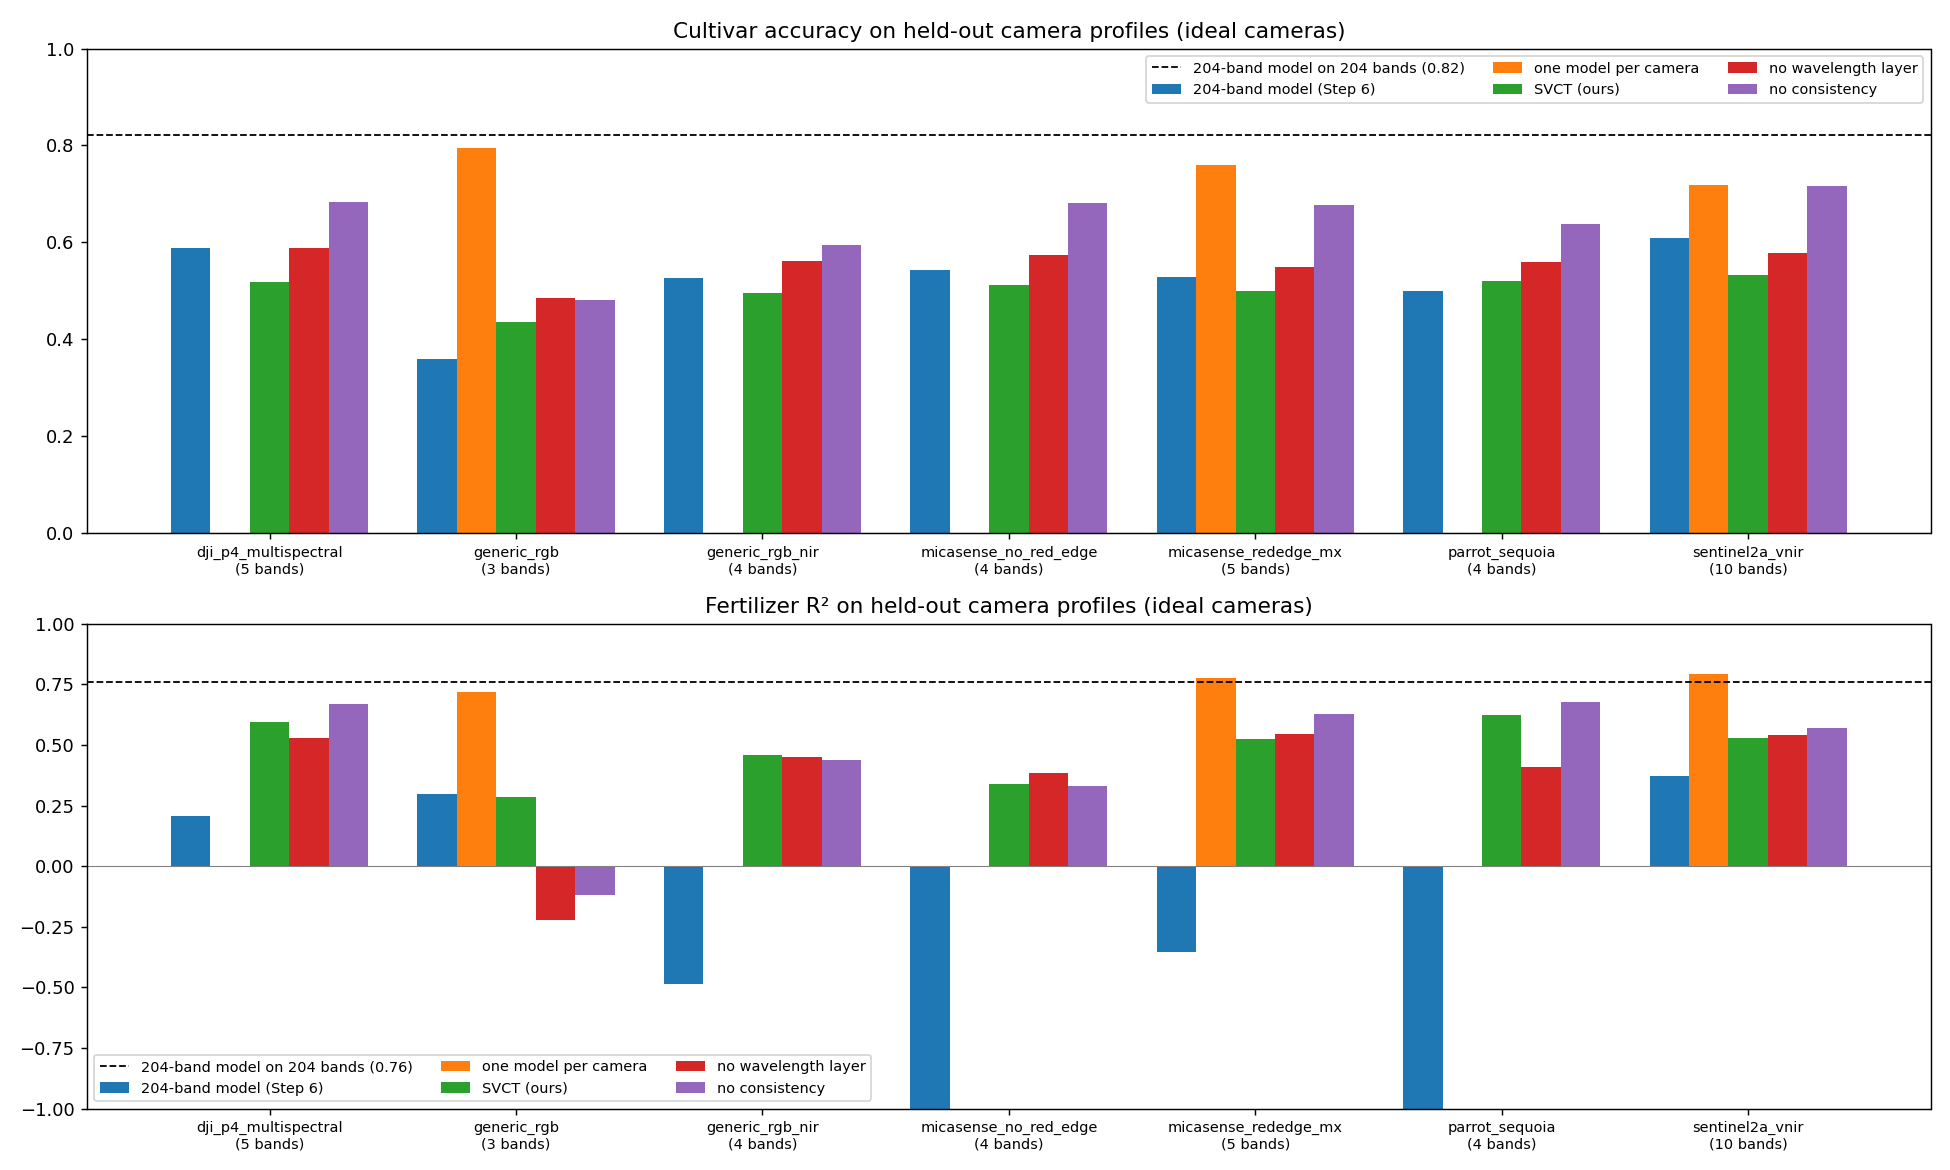

### runs/svct_interp/camera_eval.csv
camera,type,n_bands,condition,cultivar_acc,cultivar_F1,GrainWeight_R2,Gsw_R2,PhiPS2_R2,Fertilizer_R2
hyperspectral_204,hyperspectral,204,nominal,0.5719512195121951,0.558398565907417,0.5796052921467206,0.10096868345165,0.32039240691571047,0.5944129614576547
hyperspectral_204,hyperspectral,204,radiometric,0.5658536585365853,0.5502364857371703,0.5941083157801916,0.10080913020414883,0.31162718496944863,0.6028451397281275
dji_p4_multispectral,uav_multispectral,5,nominal,0.5890243902439024,0.5600129493142406,0.5809624707346104,0.0397311832430951,0.25046585067684624,0.5297868611459029
dji_p4_multispectral,uav_multispectral,5,radiometric,0.5707317073170731,0.5381876916945073,0.5319134614653624,0.02364381492856571,0.22358294049296956,0.48024229178092737
dji_p4_multispectral,uav_multispectral,5,drift+radio,0.5841463414634146,0.5514091424960186,0.49403780831232225,0.016496484464902927,0.18855579235025755,0.42499570417034316
generic_rgb,rgb,3,nominal,0.48536585

In [5]:
# comparison with Step 6 (204-band model, one model per camera)
!python scripts/plot_step7.py --baseline results/step06_camera_test/camera_eval.csv --runs "SVCT (ours)=runs/svct_main" "no wavelength layer=runs/svct_interp" "no consistency=runs/svct_nocons" --out runs/step7_compare
from IPython.display import Image, display
display(Image('runs/step7_compare/step7_compare.png'))
!for f in runs/svct_*/camera_eval.csv; do echo "### $f"; cat $f; done

## Done
When every cell has finished: **Save Version → Quick Save** with GitHub ticked → file `kaggle_runs/05_step7_svct.ipynb`. Tell Claude "done".